works on unlabel data 
no output is given when training
----------------------------
done by two ways 
1-clustering
2-association



k mean clustering

k--- define the number of pre define grps

mean-- clusters are made on mean



In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns 
import matplotlib.pyplot as plt


In [2]:
ds=pd.read_csv("flower_u.csv")


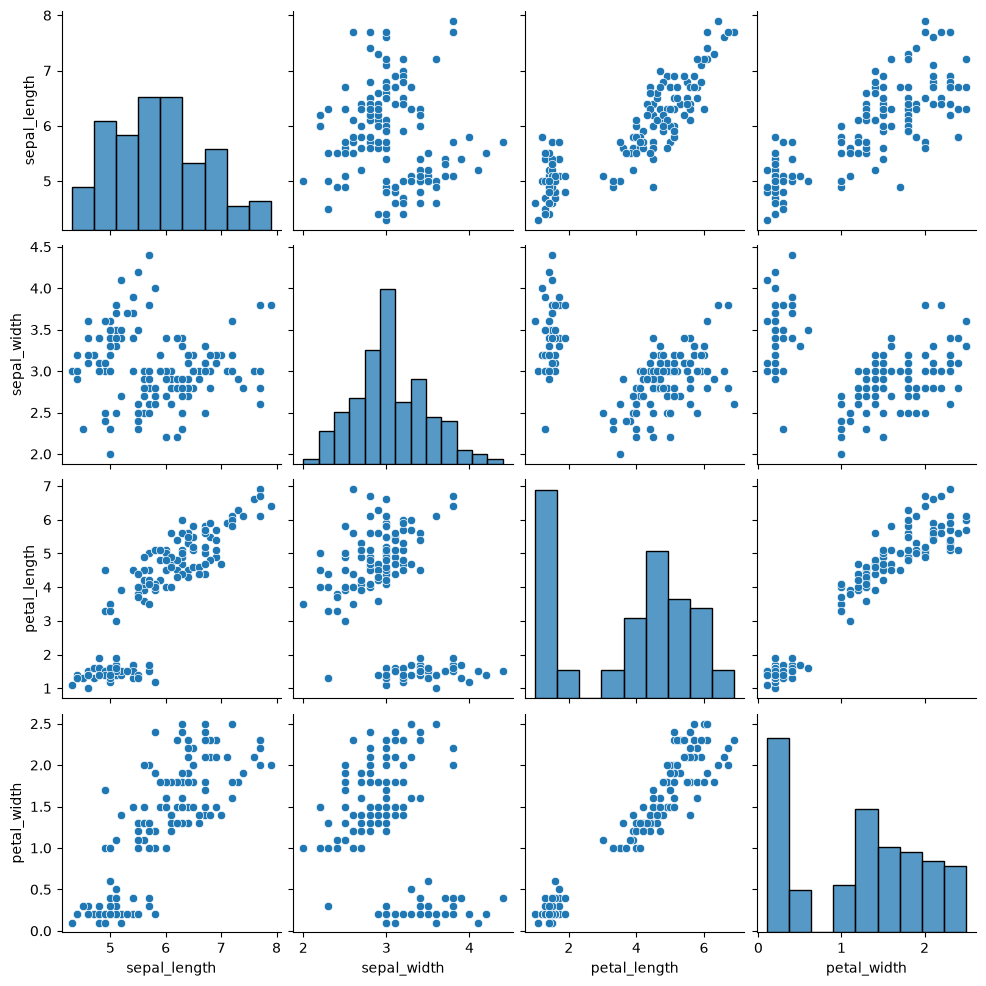

In [3]:
sns.pairplot(data=ds)

In [4]:
from sklearn.cluster import KMeans
wcss=[]
for i in range(2,21):
    km=KMeans(n_clusters=i,init="k-means++")
    km.fit(ds)
    ini=km.inertia_#give wcss value 
    wcss.append(ini)
wcss

[152.34795176035792,
 78.8556658259773,
 57.38387326549491,
 52.231247715247726,
 42.11480824175824,
 37.836557312252964,
 30.652039437600585,
 28.33670960618329,
 28.18461778559605,
 24.39204028062581,
 24.678351307189548,
 21.156767553353085,
 22.879720945720948,
 20.042861357424826,
 18.693089285714287,
 19.82861107313739,
 16.835604494190026,
 15.743863700025464,
 16.136223225604805]

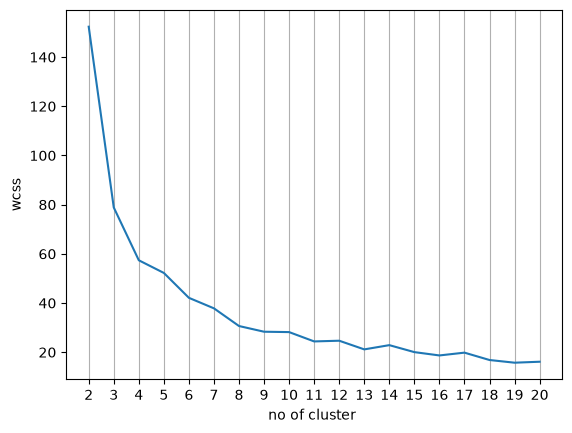

In [5]:
plt.plot([i for i in range (2,21)],wcss)
plt.xlabel ("no of cluster ")
plt.xticks([i for i in range (2,21)])
plt.ylabel("wcss")
plt.grid(axis="x")



In [6]:
#since the elbow point is at 3 we will do 3 cluster 
km=KMeans(n_clusters=3)
pred=km.fit_predict(ds)


In [7]:
ds["predicted"]=pred

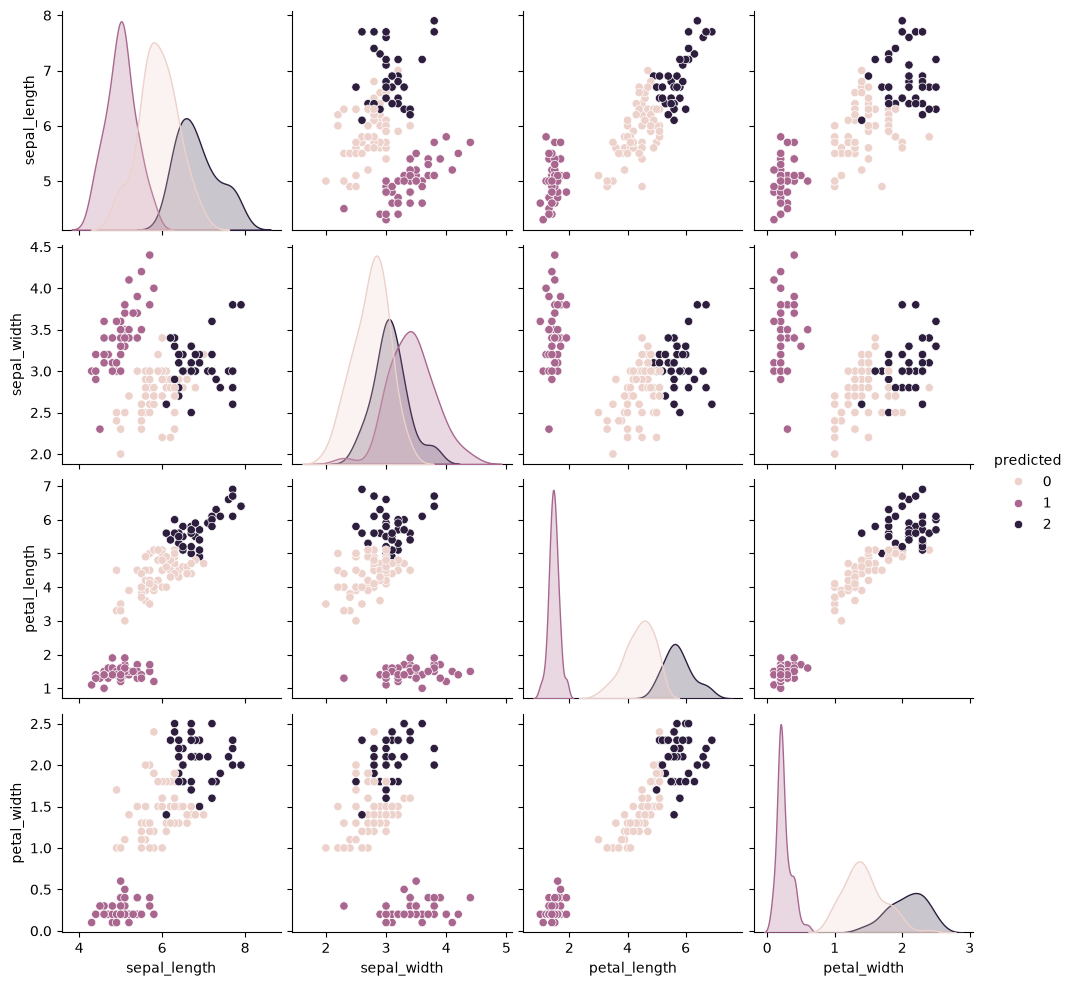

In [8]:
sns.pairplot(data=ds,hue="predicted")


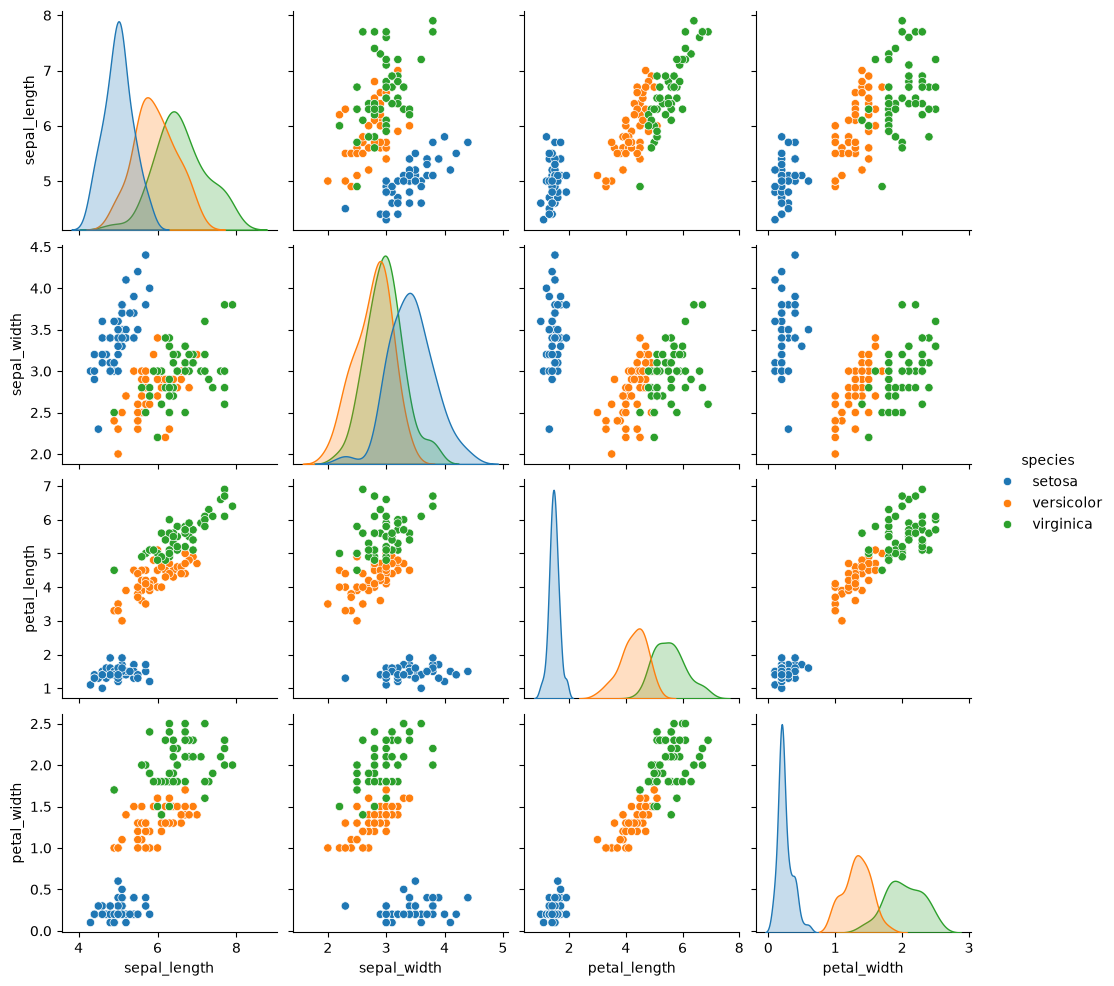

In [9]:
org_ds=pd.read_csv("iris_label.csv")
sns.pairplot(data=org_ds,hue="species")

# using silhouette score 


In [11]:
km_l=km.labels_

In [12]:
from sklearn.metrics import silhouette_score
silhouette_score(ds,labels=km_l)

0.6851559988597147

In [21]:
#to find best no of clusters
ss=[]
for i in range(2,21):
    km1=KMeans(n_clusters=i)
    km1.fit(ds)
    sh=silhouette_score(ds,km1.labels_)
    ss.append(sh)
    

In [22]:
ss


[0.6213468887749368,
 0.6851559988597147,
 0.5772635813809022,
 0.44406268264031157,
 0.40480979042291815,
 0.4038605317254962,
 0.35981299327965266,
 0.36123855933207655,
 0.32112912085453227,
 0.2820155189914649,
 0.3016601469828739,
 0.3046836124470025,
 0.30857934999195313,
 0.3192719277302364,
 0.286380618202071,
 0.2546944165624559,
 0.3025476861534341,
 0.28023016954300506,
 0.28107661093229797]

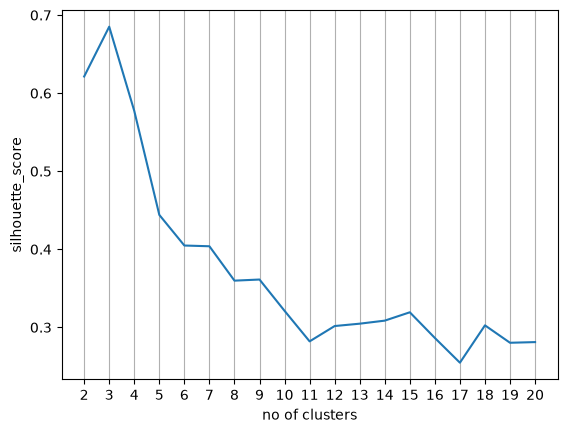

In [26]:
#to see grapically 
no_col=[j for j in range(2,21)]
plt.plot(no_col,ss)
plt.xlabel("no of clusters")
plt.ylabel("silhouette_score")
plt.xticks(no_col)
plt.grid(axis="x")
plt.show()
